# R-GCN enrichment ablation for link prediction on the F1 KGs

Which SULO enrichments make Hybrid differ from Ad-hoc in link prediction, and what does each one
contribute to each target? The units, variants and protocol are those of the node-prediction ablation
(`node_prediction/RGCN_ablation.ipynb`); only the task changes. Five units, each ablated on its own
(`f1_node_data.ABLATION_UNITS`):

| Unit | Hybrid | Ad-hoc |
|---|---|---|
| `sulo_typing` | instances also typed with their SULO superclass (`sulo:Process`, `sulo:SpatialObject`, ...) | domain class only |
| `precedesRace` | `Race sulo:precedes Race` | absent |
| `precedesSeason` | `Season sulo:precedes Season` (same predicate as `precedesRace`) | absent |
| `hasTeamMember` | `Team sulo:hasItem Driver` | absent |
| `rank_reification` | `Position/<n> sulo:isReferredToIn Position/<n>/hasRank sulo:hasValue <rank>` | `Position/<n> hasRank <rank>` |

`heldAtCircuit` → `isInCircuit` is not a unit: it renames the predicate and leaves the edges unchanged.

Each unit is ablated in both directions: **leave-one-out** (Hybrid − unit, compared with Hybrid) and
**add-one-in** (Ad-hoc + unit, compared with Ad-hoc), 12 graphs including the two controls. A variant is a
schema built with `f1_node_data.swap_units` and rendered by `build_lp_data` from the same assertions, without
`hasFinishPosition`, with the same race split and the same three target queries (Team, grid Position,
Circuit), so it differs from its control only in the unit's triples. `hasTeamMember` pairs are hidden
with their supporting entries exactly as in the main notebooks (Ad-hoc and Hybrid − `hasTeamMember` have none).

**Why**: in the main runs Hybrid scored below Ad-hoc on some targets (R-GCN: Position; GraphSAGE: Team
and Circuit), the only Ad-hoc vs Hybrid differences in the project. Hypotheses stated before this run:
`rank_reification` puts a Position candidate's rank one hop further away (Position); `sulo_typing` adds
type edges into a few SULO class hubs that GraphSAGE-mean averages into every neighbourhood (Team,
Circuit); `hasTeamMember` is the other candidate for Team.

The model is an R-GCN encoder (`RGCNModel`, one weight per relation type through the basis decomposition) with a DistMult decoder, as in `link_prediction_rgcn.ipynb`. Every variant is
trained with the **Hybrid winner's configuration** from that notebook's tuning run (user, 2026-11-04:
the same configuration for all 12 graphs, so only the graph changes; per-variant tuning would mix tuning
noise into every delta). Each seed in `FINAL_SEEDS` trains on the train races with early stopping on pooled
val MRR, and the best-val weights are scored on the test races, with the train + val facts as context. This
protocol differs from the main notebooks' train+val retrain, so the controls are re-run here and compared
with the main results only in the controls cell. Limitation: the configuration was tuned on Hybrid, so it may
suit Hybrid-like graphs slightly better; this biases leave-one-out deltas slightly negative and add-one-in
deltas slightly positive. This notebook and its GraphSAGE counterpart differ only in the encoder.

In [1]:
# Must run before CUDA is initialised: avoids fragmentation OOMs across a long sweep.
import os
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'

import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "f1_population.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from f1_node_data import ABLATION_UNITS, ABLATION_VARIANTS, ablation_schema, load_population
from f1_population import SCHEMA_FILES, read_schema
from link_prediction.link_prediction_tools import (
    LP_ABLATION_METRICS, TARGETS, LinkPredictor, build_lp_data, evaluate_lp_on, frequency_baseline, leaked_facts,
    race_split, run_lp_ablation_variant, train_lp_model,
)
from node_prediction.gnn_tools import cleanup, limit_cuda_memory_to_free_vram, set_seed, summarize_ablation
from node_prediction.models import RGCNModel

MAIN_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "rgcn"
TUNING_CSV = MAIN_DIR / "hybrid_sulo_sequential_tuning_results.csv"
OUT_DIR = ROOT / "outputs" / "f1" / "link_prediction" / "ablation" / "rgcn"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(torch.__version__, "| CUDA:", torch.cuda.is_available())
# WSL2 would otherwise overcommit VRAM into RAM and fail with a driver error instead of an OOM,
# which the run could not skip.
if torch.cuda.is_available():
    print(f"CUDA memory cap: {limit_cuda_memory_to_free_vram() / 2**30:.2f} GiB")

/home/domin/miniconda3/envs/sulo/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.7.0+cu126 | CUDA: True
CUDA memory cap: 10.48 GiB


## Data

Each variant is rendered from `data/f1/assertions.csv` with its own schema (`build_lp_data`, same as the main
notebooks). The race split is computed once and shared by all variants. The cell checks that every variant
asks the same queries (heads, answers and candidates compared by IRI, since node ids differ between graphs)
and that nothing of a hidden race is reachable in any variant, with the training-time hiding (val + test
races) and the test-time hiding (test races) (`leaked_facts`, as in `link_prediction_setup.ipynb`). The table
shows each variant's size and how it differs from its control.

In [2]:
entities, assertions = load_population(ROOT / "data" / "f1")
split = race_split(entities, seed=42)
schemas = {kg: read_schema(str(ROOT / path)) for kg, path in SCHEMA_FILES.items()}

lp_data = {
    variant: build_lp_data(base, entities, assertions, split, ablation_schema(variant, schemas))
    for variant, (base, _, _) in ABLATION_VARIANTS.items()
}
controls = {variant: base for variant, (base, _, _) in ABLATION_VARIANTS.items()}


def queries(d):
    """Every target's (head IRIs, answers, races, candidate IRIs)."""
    iri_of = {i: iri for iri, i in d.node_ids.items()}
    return {name: ([iri_of[h] for h in t.head.tolist()], t.answer.tolist(), t.race.tolist(),
                   [iri_of[c] for c in t.candidates.tolist()]) for name, t in d.targets.items()}


reference = queries(lp_data["adhoc"])
for variant, d in lp_data.items():
    assert d.races == lp_data["adhoc"].races and queries(d) == reference, f"{variant} asks other queries"
    for hidden in (d.race_split >= 1, d.race_split == 2):
        leaks = leaked_facts(d, hidden)
        assert set(leaks.values()) == {0}, f"{variant} leaks hidden facts: {leaks}"

stats = pd.DataFrame({
    variant: {
        "control": controls[variant],
        "nodes": d.data.num_nodes,
        "edges (fwd + inv)": d.data.edge_index.size(1),
        "relation types (fwd + inv)": d.num_relations,
        "feature keys": len(d.vocabulary),
        "hasTeamMember pairs": d.member_edges.size(1) // 2,
    }
    for variant, d in lp_data.items()
}).T
for col in ["nodes", "edges (fwd + inv)", "relation types (fwd + inv)", "hasTeamMember pairs"]:
    stats[f"Δ {col}"] = stats[col].values - stats.loc[stats["control"], col].values
stats

,control,nodes,edges (fwd + inv),relation types (fwd + inv),feature keys,hasTeamMember pairs,Δ nodes,Δ edges (fwd + inv),Δ relation types (fwd + inv),Δ hasTeamMember pairs
hybrid_sulo,hybrid_sulo,58193,687354,64,1398,1941,0,0,0,0
adhoc,adhoc,58154,594834,58,1392,0,0,0,0,0
hybrid_minus_sulo_typing,hybrid_sulo,58189,601156,64,1394,1941,-4,-86198,0,0
hybrid_minus_precedesRace,hybrid_sulo,58193,685202,64,1398,1941,0,-2152,0,0
hybrid_minus_precedesSeason,hybrid_sulo,58193,687202,64,1398,1941,0,-152,0,0
hybrid_minus_hasTeamMember,hybrid_sulo,58193,683472,62,1398,0,0,-3882,-2,-1941
hybrid_minus_rank_reification,hybrid_sulo,58159,687218,62,1397,1941,-34,-136,-2,0
adhoc_plus_sulo_typing,adhoc,58159,681032,58,1397,0,5,86198,0,0
adhoc_plus_precedesRace,adhoc,58154,596986,60,1392,0,0,2152,2,0
adhoc_plus_precedesSeason,adhoc,58154,594986,60,1392,0,0,152,2,0


## Constants

The training constants are the main notebook's (`link_prediction_rgcn.ipynb`), with the same sources. The
architecture and optimiser come from the Hybrid winner of its tuning run, read from its CSV, not hardcoded.
R-GCN keeps the Hybrid winner's basis count for every variant; it is at most each variant's relation count R.

In [3]:
# Full-batch, so one epoch = one gradient step. Max epochs 400 = the top of GraphGym's design space
# {100, 200, 400} (You et al. 2020, Section 4). Patience 50: no literature value (user choice,
# 2026-10-21, as in node prediction). Same values as the main notebooks.
#   https://arxiv.org/abs/2011.08843
EPOCHS = 400
PATIENCE = 50

# Early-stopping warm-up (user, 2026-10-29, as in node prediction): epochs 0-49 are trained but neither
# checkpointed nor counted towards patience, as Keras' EarlyStopping(start_from_epoch). No literature value.
#   https://keras.io/api/callbacks/early_stopping/
START_FROM_EPOCH = 50

# Node input embedding size: the GraphSAGE reference implementation recommends learned identity
# features of 64-256 dims (README, --identity_dim). Also the embedding dim of a 1-layer model.
#   https://github.com/williamleif/GraphSAGE#readme
FEATURE_DIM = 256

# Dropout: PyG's R-GCN example uses p=0.2 between the RGCNConv layers; the original
# R-GCN paper uses no dropout for entity classification.
#   https://github.com/pyg-team/pytorch_geometric/blob/master/examples/rgcn_link_pred.py
DROPOUT = 0.2

# Share of the training races whose target facts are hidden from message passing and supervised in an
# epoch (redrawn every epoch; the rest are context). User choice (2026-11-02): 0.3 is the value of PyG's
# link-prediction tutorial for RandomLinkSplit(disjoint_train_ratio), which exists to keep supervision
# edges out of message passing; R-GCN's link-prediction edge dropout of 0.4 is the closest value from
# Schlichtkrull et al. 2018.
#   https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.transforms.RandomLinkSplit.html
#   https://arxiv.org/abs/1703.06103
DISJOINT_TRAIN_RATIO = 0.3

# The main notebooks' final-evaluation seeds (user, 2026-10-20); results are mean ± std over them.
FINAL_SEEDS = [0, 1, 2, 3, 4]

# Fixed configuration: the Hybrid winner (one phase-4 row per final seed, all with the same config).
winners = pd.read_csv(TUNING_CSV).query("phase == '4_Final_Test_Evaluation'")
config_columns = ["hidden_dim", "layers", "num_bases", "lr", "weight_decay"]
assert len(winners.drop_duplicates(config_columns)) == 1, "phase-4 rows disagree on the configuration"
winner = winners.iloc[0]
DEPTH = int(winner["layers"])
HIDDEN = [int(winner["hidden_dim"])] * (DEPTH - 1)
BASES = None if pd.isna(winner["num_bases"]) else int(winner["num_bases"])
assert BASES is None or all(BASES <= d.num_relations for d in lp_data.values()), "bases > R in a variant"
LR, WD = float(winner["lr"]), float(winner["weight_decay"])
print(f"Hybrid winner: hidden {HIDDEN}, layers {DEPTH}, bases {BASES}, lr {LR}, wd {WD}")

Hybrid winner: hidden [64, 64], layers 3, bases 2, lr 0.005, wd 0.0


In [4]:
def model_factory(d):
    """(hidden_list, bases) -> fresh LinkPredictor for one variant; everything variant-specific is bound here.
    The embedding dim is the last hidden dim; a 1-layer model has none and embeds in FEATURE_DIM."""
    def build(hidden_list, bases):
        dim = hidden_list[-1] if hidden_list else FEATURE_DIM
        encoder = RGCNModel(
            num_keys=len(d.vocabulary), feature_dim=FEATURE_DIM, hidden_channels_list=hidden_list,
            num_relations=d.num_relations, num_bases=bases, out_channels=dim, dropout=DROPOUT,
        )
        return LinkPredictor(encoder, len(TARGETS), dim)
    return build

## Pipeline check: shuffled answers

Trains the fixed configuration on every variant with every target's answers permuted across its facts. The
graph then says nothing about a query's answer, so the test MRR must stay at the frequency baseline (ranking
candidates by how often they answered earlier races): otherwise the answer tensor reaches the model's inputs
somewhere in the variant's pipeline. Held-out *true* facts left in a graph are checked by `leaked_facts` in the
data cell.

In [5]:
control = {}
for variant, d in lp_data.items():
    generator = torch.Generator().manual_seed(0)
    shuffled = replace(d, targets={n: replace(t, answer=t.answer[torch.randperm(len(t.answer), generator=generator)])
                                   for n, t in d.targets.items()})
    set_seed(FINAL_SEEDS[0])
    model = model_factory(d)(HIDDEN, BASES)
    model, _ = train_lp_model(model, shuffled, epochs=EPOCHS, lr=LR, weight_decay=WD, patience=PATIENCE,
                              disjoint_ratio=DISJOINT_TRAIN_RATIO, seed=FINAL_SEEDS[0],
                              start_from_epoch=START_FROM_EPOCH)
    test, chance = evaluate_lp_on(model, shuffled, "test"), frequency_baseline(shuffled, "test")
    control[variant] = {f"{t} {kind}": m[t]["mrr"] for kind, m in (("gnn", test), ("frequency", chance)) for t in m}
    del model, shuffled
    cleanup()

pd.DataFrame(control).T.round(4)

Epoch 000 | Train Loss: 5.2595 | Val MRR: 0.0937 (team 0.0518, position 0.1389, circuit 0.0713) | Grad Norm: 9.8117
Epoch 001 | Train Loss: 4.7596 | Val MRR: 0.1287 (team 0.1024, position 0.1580, circuit 0.0928) | Grad Norm: 3.9830
Epoch 002 | Train Loss: 4.5093 | Val MRR: 0.1042 (team 0.0511, position 0.1602, circuit 0.1009) | Grad Norm: 2.0055
Epoch 003 | Train Loss: 4.4945 | Val MRR: 0.1474 (team 0.1364, position 0.1604, circuit 0.1178) | Grad Norm: 1.9281
Epoch 004 | Train Loss: 4.3890 | Val MRR: 0.1575 (team 0.1556, position 0.1603, circuit 0.1388) | Grad Norm: 1.7609
Epoch 005 | Train Loss: 4.2739 | Val MRR: 0.1660 (team 0.1726, position 0.1607, circuit 0.1272) | Grad Norm: 1.3795
Epoch 006 | Train Loss: 4.2425 | Val MRR: 0.1723 (team 0.1853, position 0.1602, circuit 0.1352) | Grad Norm: 1.1050
Epoch 007 | Train Loss: 4.2366 | Val MRR: 0.1734 (team 0.1874, position 0.1602, circuit 0.1407) | Grad Norm: 1.2122
Epoch 008 | Train Loss: 4.2268 | Val MRR: 0.1740 (team 0.1885, position 

,team gnn,position gnn,circuit gnn,pooled gnn,team frequency,position frequency,circuit frequency,pooled frequency
hybrid_sulo,0.2081,0.1683,0.1704,0.1884,0.2085,0.1625,0.1784,0.186
adhoc,0.2069,0.1650,0.1794,0.1864,0.2085,0.1625,0.1784,0.186
hybrid_minus_sulo_typing,0.2093,0.1680,0.1795,0.1890,0.2085,0.1625,0.1784,0.186
hybrid_minus_precedesRace,0.2084,0.1664,0.1711,0.1877,0.2085,0.1625,0.1784,0.186
hybrid_minus_precedesSeason,0.2081,0.1672,0.1985,0.1885,0.2085,0.1625,0.1784,0.186
hybrid_minus_hasTeamMember,0.2086,0.1662,0.1700,0.1876,0.2085,0.1625,0.1784,0.186
hybrid_minus_rank_reification,0.2070,0.1666,0.1812,0.1873,0.2085,0.1625,0.1784,0.186
adhoc_plus_sulo_typing,0.2087,0.1634,0.1711,0.1864,0.2085,0.1625,0.1784,0.186
adhoc_plus_precedesRace,0.2090,0.1677,0.1790,0.1887,0.2085,0.1625,0.1784,0.186
adhoc_plus_precedesSeason,0.2067,0.1659,0.1806,0.1868,0.2085,0.1625,0.1784,0.186


## Ablation runs

Each of the 12 graphs is trained once per seed in `FINAL_SEEDS`. Rows are appended to
`ablation_results.csv` as each seed finishes: after a crash, finished (variant, seed) pairs are
skipped and failed ones are retried. Constants are not checked, so move the CSV away after changing one.

In [6]:
csv_path = OUT_DIR / "ablation_results.csv"
for variant, d in lp_data.items():
    run_lp_ablation_variant(
        model_factory(d), d, variant, HIDDEN, BASES, LR, WD,
        epochs=EPOCHS, patience=PATIENCE, start_from_epoch=START_FROM_EPOCH,
        disjoint_ratio=DISJOINT_TRAIN_RATIO, seeds=FINAL_SEEDS,
        save_dir=f"{OUT_DIR / 'checkpoints'}/", csv_path=csv_path,
    )
    cleanup()

results = pd.read_csv(csv_path)   # every variant's rows, including failed seeds of earlier variants
# An OOM-ed seed is logged, not fatal: every variant needs all its seeds to be compared.
failed = results[results["status"] != "ok"]
assert failed.empty, f"Ablation runs that did not finish:\n{failed[['variant', 'seed', 'status']]}"
assert len(results) == len(lp_data) * len(FINAL_SEEDS)
early = results[results["best_epoch"] < START_FROM_EPOCH]
assert early.empty, f"Rows selected inside the warm-up (delete and re-run them):\n{early[['variant', 'seed', 'best_epoch']]}"


=== LP ablation hybrid_sulo | seed 0 ===
Epoch 000 | Train Loss: 5.2497 | Val MRR: 0.0997 (team 0.0588, position 0.1448, circuit 0.0570) | Grad Norm: 9.8234
Epoch 001 | Train Loss: 4.7197 | Val MRR: 0.1375 (team 0.1133, position 0.1659, circuit 0.0746) | Grad Norm: 3.8859
Epoch 002 | Train Loss: 4.5399 | Val MRR: 0.1202 (team 0.0761, position 0.1679, circuit 0.0925) | Grad Norm: 2.1496
Epoch 003 | Train Loss: 4.4586 | Val MRR: 0.1532 (team 0.1412, position 0.1678, circuit 0.1099) | Grad Norm: 1.8338
Epoch 004 | Train Loss: 4.3844 | Val MRR: 0.1608 (team 0.1547, position 0.1680, circuit 0.1455) | Grad Norm: 1.8800
Epoch 005 | Train Loss: 4.2511 | Val MRR: 0.1662 (team 0.1646, position 0.1680, circuit 0.1615) | Grad Norm: 1.4475
Epoch 006 | Train Loss: 4.2053 | Val MRR: 0.1771 (team 0.1861, position 0.1678, circuit 0.1758) | Grad Norm: 1.0826
Epoch 007 | Train Loss: 4.2049 | Val MRR: 0.1766 (team 0.1858, position 0.1678, circuit 0.1579) | Grad Norm: 1.2566
Epoch 008 | Train Loss: 4.2042

## Results

Mean ± std over `FINAL_SEEDS` per variant, plus the difference between its mean and its control's mean
(`delta_*`), pooled and **per target**: leave-one-out against Hybrid, add-one-in against Ad-hoc. A negative
leave-one-out delta means Hybrid loses something without the unit; a positive add-one-in delta means the unit
helps Ad-hoc on its own. Differences are reported as mean ± std, with no significance test (as in the main
notebooks). Circuit has ~115 test races, so its deltas are the noisiest.

In [7]:
summary = summarize_ablation(results, controls, metrics=LP_ABLATION_METRICS, delta_metrics=LP_ABLATION_METRICS)
summary.round(4).to_csv(OUT_DIR / "ablation_summary.csv")
summary.round(4)

,control,n_seeds,val_mrr_mean,val_mrr_std,test_mrr_mean,test_mrr_std,test_team_mrr_mean,test_team_mrr_std,test_position_mrr_mean,test_position_mrr_std,test_circuit_mrr_mean,test_circuit_mrr_std,delta_val_mrr,delta_test_mrr,delta_test_team_mrr,delta_test_position_mrr,delta_test_circuit_mrr
variant,,,,,,,,,,,,,,,,,
hybrid_sulo,hybrid_sulo,5,0.5156,0.0032,0.5102,0.0047,0.7151,0.0074,0.2738,0.0028,0.9279,0.0079,0.0000,0.0000,0.0000,0.0000,0.0000
adhoc,adhoc,5,0.5858,0.0361,0.5758,0.0352,0.7184,0.0102,0.4090,0.0761,0.9166,0.0169,0.0000,0.0000,0.0000,0.0000,0.0000
hybrid_minus_sulo_typing,hybrid_sulo,5,0.5194,0.0032,0.5126,0.0048,0.7221,0.0066,0.2713,0.0039,0.9297,0.0083,0.0038,0.0023,0.0070,-0.0025,0.0018
hybrid_minus_precedesRace,hybrid_sulo,5,0.5181,0.0032,0.5134,0.0042,0.7236,0.0075,0.2716,0.0039,0.9232,0.0086,0.0024,0.0031,0.0085,-0.0023,-0.0047
hybrid_minus_precedesSeason,hybrid_sulo,5,0.5156,0.0043,0.5123,0.0044,0.7187,0.0088,0.2744,0.0047,0.9267,0.0048,-0.0000,0.0021,0.0037,0.0005,-0.0012
hybrid_minus_hasTeamMember,hybrid_sulo,5,0.5202,0.0034,0.5167,0.0039,0.7261,0.0057,0.2762,0.0028,0.9197,0.0108,0.0046,0.0065,0.0110,0.0024,-0.0082
hybrid_minus_rank_reification,hybrid_sulo,5,0.5985,0.0093,0.5908,0.0073,0.7206,0.0147,0.4384,0.0174,0.9164,0.0092,0.0829,0.0806,0.0055,0.1646,-0.0116
adhoc_plus_sulo_typing,adhoc,5,0.5777,0.0363,0.5681,0.0332,0.7228,0.0041,0.3874,0.0701,0.9315,0.0086,-0.0080,-0.0077,0.0044,-0.0216,0.0149
adhoc_plus_precedesRace,adhoc,5,0.5940,0.0202,0.5826,0.0183,0.7162,0.0133,0.4257,0.0314,0.9169,0.0083,0.0083,0.0068,-0.0022,0.0167,0.0003


### Controls vs the main runs

The two controls share the Hybrid winner's configuration and skip the train+val retrain; in the main runs each
KG used its own winner. If the Hybrid − Ad-hoc gap of the main runs also appears between the controls, it comes
from the graphs; if it shrinks, part of it came from the two KGs' different tuned configurations.

In [8]:
test_mrr = LP_ABLATION_METRICS[1:]
main = {kg: pd.read_csv(MAIN_DIR / f"{kg}_sequential_tuning_results.csv")
            .query("phase == '4_Final_Test_Evaluation'")[test_mrr].mean()
        for kg in ("adhoc", "hybrid_sulo")}
ablation = {kg: summary.loc[kg, [f"{m}_mean" for m in test_mrr]].set_axis(test_mrr) for kg in ("adhoc", "hybrid_sulo")}
pd.DataFrame({
    "main: Ad-hoc (own winner)": main["adhoc"],
    "main: Hybrid": main["hybrid_sulo"],
    "main: Hybrid − Ad-hoc": main["hybrid_sulo"] - main["adhoc"],
    "controls: Ad-hoc (Hybrid winner)": ablation["adhoc"],
    "controls: Hybrid": ablation["hybrid_sulo"],
    "controls: Hybrid − Ad-hoc": ablation["hybrid_sulo"] - ablation["adhoc"],
}).T.round(4)

,test_mrr,test_team_mrr,test_position_mrr,test_circuit_mrr
main: Ad-hoc (own winner),0.578511,0.727024,0.404748,0.934183
main: Hybrid,0.514692,0.720994,0.27668,0.934075
main: Hybrid − Ad-hoc,-0.063819,-0.00603,-0.128069,-0.000109
controls: Ad-hoc (Hybrid winner),0.57581,0.718392,0.409015,0.916634
controls: Hybrid,0.510243,0.715093,0.273849,0.927937
controls: Hybrid − Ad-hoc,-0.065567,-0.003299,-0.135166,0.011303


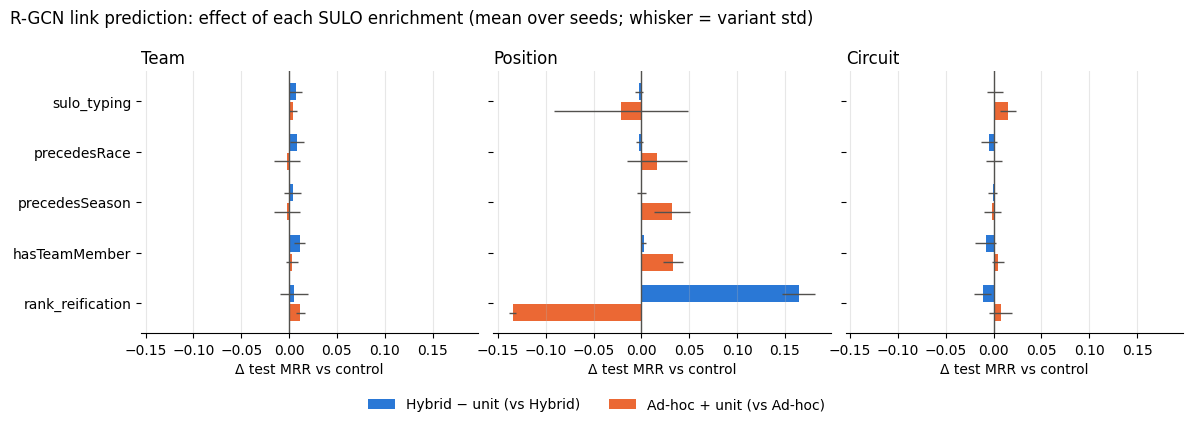

In [9]:
units = list(ABLATION_UNITS)
directions = [
    ("hybrid_minus", "Hybrid − unit (vs Hybrid)", "#2a78d6"),
    ("adhoc_plus", "Ad-hoc + unit (vs Ad-hoc)", "#eb6834"),
]
y = np.arange(len(units))
# One x scale for all targets, so their deltas compare directly.
fig, axes = plt.subplots(1, len(TARGETS), figsize=(12, 4.2), sharex=True, sharey=True)
for ax, target in zip(axes, TARGETS):
    metric = f"test_{target}_mrr"
    for offset, (prefix, label, color) in zip((-0.19, 0.19), directions):
        rows = summary.loc[[f"{prefix}_{u}" for u in units]]
        ax.barh(y + offset, rows[f"delta_{metric}"], height=0.34, color=color, label=label,
                xerr=rows[f"{metric}_std"], error_kw=dict(elinewidth=1, ecolor="#52514e", capsize=0))
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set_title(target.capitalize(), loc="left")
    ax.set_xlabel("Δ test MRR vs control")
    ax.grid(axis="x", alpha=0.3)
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].set_yticks(y, units)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, loc="lower center", ncol=2)
fig.suptitle("R-GCN link prediction: effect of each SULO enrichment (mean over seeds; whisker = variant std)",
             x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(OUT_DIR / "ablation_delta_test_mrr.png", dpi=200)
plt.show()

## Limitation: runs ended by the epoch cap

A seed whose best epoch is ≥ `EPOCHS − PATIENCE` was cut off by the `EPOCHS` cap while possibly still
improving, so its score may be understated (the same limitation as in the main notebooks).

In [10]:
results[results["best_epoch"] >= EPOCHS - PATIENCE][["variant", "seed", "best_epoch", "val_mrr", "test_mrr",
                                                        *(f"test_{t}_mrr" for t in TARGETS)]]

,variant,seed,best_epoch,val_mrr,test_mrr,test_team_mrr,test_position_mrr,test_circuit_mrr
0,hybrid_sulo,0,376,0.515724,0.508139,0.709368,0.275302,0.932238
1,hybrid_sulo,1,396,0.519769,0.516017,0.724013,0.276298,0.933310
2,hybrid_sulo,2,393,0.514450,0.508950,0.712806,0.274143,0.914807
3,hybrid_sulo,3,387,0.511077,0.504190,0.707615,0.269103,0.926429
4,hybrid_sulo,4,393,0.517058,0.513920,0.721662,0.274396,0.932902
5,adhoc,0,394,0.604558,0.594921,0.723525,0.443511,0.923794
7,adhoc,2,389,0.595191,0.585951,0.725375,0.423873,0.896490
8,adhoc,3,385,0.521760,0.513457,0.721912,0.274347,0.906447
9,adhoc,4,399,0.607588,0.597902,0.720767,0.451961,0.940705
10,hybrid_minus_sulo_typing,0,364,0.520034,0.513122,0.722021,0.272464,0.929972
